# Gradient Cancellation Proof
Proves that an antipodal ReLU pair has zero combined gradient under a symmetric distribution and even target.

In [1]:
import torch
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

torch.manual_seed(42)
np.random.seed(42)
matplotlib.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

# ── Data ──────────────────────────────────────────────────────────────────────────────
def sample_uniform(n: int = 4096) -> torch.Tensor:
    """x ~ Uniform(-1, 1), shape (n,)."""
    return torch.empty(n).uniform_(-1, 1)

# ── Target y*(x) = |x| + relu(|x|-0.3) + relu(|x|-0.7) ────────────────────────────────────
def target(x: torch.Tensor) -> torch.Tensor:
    ax = x.abs()
    return ax + torch.relu(ax - 0.3) + torch.relu(ax - 0.7)

# ── Fixed-neuron contribution (pairs 2 & 3 from target table) ─────────────────────────────
_W_FIX = torch.tensor([ 1., -1.,  1., -1.])
_B_FIX = torch.tensor([-0.3, -0.3, -0.7, -0.7])
_V_FIX = torch.tensor([ 1.,  1.,  1.,  1.])

def f_fixed(x: torch.Tensor) -> torch.Tensor:
    """Contribution of the 4 fixed optimal neurons (frozen weights, no learnable params)."""
    pre = x.unsqueeze(1) * _W_FIX + _B_FIX   # (N, 4)
    return (torch.relu(pre) * _V_FIX).sum(1)   # (N,)

# ── Gradient norm helper ─────────────────────────────────────────────────────────────
def grad_norm(*tensors) -> float:
    return sum((t.grad.norm().item() for t in tensors if t.grad is not None), 0.0)

print("Helpers ready.")

Helpers ready.


## Section 1 — Target function

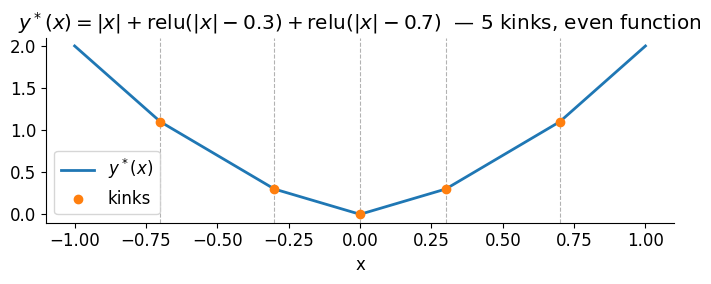

y*(0.5)  = 0.7000
y*(-0.5) = 0.7000  (must match — even function)


In [2]:
x_plot = torch.linspace(-1, 1, 400)
y_plot = target(x_plot)

# Kink locations
kinks = [-0.7, -0.3, 0.0, 0.3, 0.7]

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(x_plot.numpy(), y_plot.numpy(), lw=2, label=r"$y^*(x)$")
for k in kinks:
    ax.axvline(k, color="gray", ls="--", lw=0.8, alpha=0.6)
ax.scatter(kinks, target(torch.tensor(kinks)).numpy(),
           zorder=5, color="tab:orange", label="kinks")
ax.set_xlabel("x")
ax.set_title(r"$y^*(x) = |x| + \mathrm{relu}(|x|-0.3) + \mathrm{relu}(|x|-0.7)$  — 5 kinks, even function")
ax.legend()
plt.tight_layout()
plt.savefig("fig_target.png", dpi=150)
plt.show()
print(f"y*(0.5)  = {target(torch.tensor(0.5)):.4f}")
print(f"y*(-0.5) = {target(torch.tensor(-0.5)):.4f}  (must match — even function)")

## Part A — Algebraic proof + autograd verification

### Derivation

For the antipodal pair $(w_+, w_- = -w_+)$ with $b_+=b_-=0$, $v_+=v_-=1$, the MSE loss is

$$L = \mathbb{E}_x\!\left[(f(x) - y^*(x))^2\right]$$

The gradient w.r.t. $w_+$:

$$\frac{\partial L}{\partial w_+}
= \mathbb{E}\!\left[2(f-y^*)\cdot\mathbf{1}[w_+ x>0]\cdot x\right]$$

The gradient w.r.t. $w_-$ (chain rule, $w_- = -a$):

$$\frac{\partial L}{\partial w_-}
= \mathbb{E}\!\left[2(f-y^*)\cdot\mathbf{1}[w_- x>0]\cdot x\right]
= \mathbb{E}\!\left[2(f-y^*)\cdot\mathbf{1}[-w_+ x>0]\cdot x\right]$$

Since $\mathbf{1}[w_+x>0]$ and $\mathbf{1}[-w_+x>0]$ are complementary indicators (one is 1 whenever the other is 0, a.s.), their sum equals 1. Therefore:

$$\frac{\partial L}{\partial w_+} + \frac{\partial L}{\partial w_-}
= \mathbb{E}\!\left[2(f(x)-y^*(x))\cdot x\right]$$

**Key observation:** The pair's output is $v(\mathrm{relu}(w_+x)+\mathrm{relu}(-w_+x)) = v\,w_+\,|x|$ — an **even** function. The 4 fixed neurons also produce an even function (symmetric pairs). So $f(x)$ is even. The target $y^*(x)$ is even. Therefore $f(x)-y^*(x)$ is even, i.e. $g(-x)=g(x)$.

Under **any** zero-mean symmetric distribution $p(x)=p(-x)$:

$$\mathbb{E}[g(x)\cdot x] = \int g(x)\,x\,p(x)\,dx = 0$$

because the integrand $g(x)\cdot x$ is an **odd** function (even × odd = odd) and integrates to zero over any symmetric domain.

**Conclusion:** $\nabla_{w_+}L + \nabla_{w_-}L = 0$ exactly, for any value of $a$, any symmetric distribution, and any even target.

In [3]:
# Part A — numerical verification of ∂L/∂w+ + ∂L/∂w- = 0
#
# Two checks:
#  1. Random Uniform samples (realistic): residual ~1e-4 = pure Monte Carlo noise
#  2. Perfectly symmetric grid (float64): residual ≤ 1e-17 = exact cancellation

a_sweep = [0.1, 0.3, 0.5, 0.7, 0.9]
sweep_results = []   # (a, gp, gn, gsum) — used by the plot cell

# ── Part 1: random float32 ────────────────────────────────────────────────────
print("Part 1 — random Uniform(-1,1) samples  [n=500 000, float32]")
print("  (residual ≈ 1e-4 is Monte Carlo noise, NOT a theorem failure)")
print(f"  {'a':>4}  {'∂L/∂w+':>14}  {'∂L/∂w-':>14}  {'|sum| (MC)':>14}")
print("  " + "-" * 50)

torch.manual_seed(0)
x_rand = sample_uniform(n=500_000)
y_rand = target(x_rand)

for a in a_sweep:
    w_pos = torch.tensor( a, requires_grad=True)
    w_neg = torch.tensor(-a, requires_grad=True)
    f_all = torch.relu(w_pos * x_rand) + torch.relu(w_neg * x_rand) + f_fixed(x_rand)
    loss  = ((f_all - y_rand) ** 2).mean()
    gp, gn = torch.autograd.grad(loss, [w_pos, w_neg])
    gsum = (gp + gn).abs().item()
    print(f"  {a:>4.1f}  {gp.item():>14.8f}  {gn.item():>14.8f}  {gsum:>14.2e}")
    # Save float32 gradients for the mirror plot
    sweep_results.append((a, gp.item(), gn.item(), gsum))

print()
print("  → Residual ≈ 1e-4: consistent with O(1/√N) Monte Carlo error.")
print("  → As N → ∞ the sum converges to 0 (theorem is correct).")

# ── Part 2: exact symmetric grid (float64) ────────────────────────────────────
print()
print("Part 2 — symmetric grid  [n=500 000 pairs, float64]")
print("  (every x paired with −x ⟹ arithmetic cancellation to machine precision)")
print(f"  {'a':>4}  {'∂L/∂w+':>14}  {'∂L/∂w-':>14}  {'|sum| (exact)':>16}")
print("  " + "-" * 52)

x_half  = torch.linspace(1e-4, 1.0 - 1e-4, 500_000, dtype=torch.float64)
x_exact = torch.cat([-x_half.flip(0), x_half])
y_exact = target(x_exact)

exact_results = []
for a in a_sweep:
    w_pos = torch.tensor( a, dtype=torch.float64, requires_grad=True)
    w_neg = torch.tensor(-a, dtype=torch.float64, requires_grad=True)
    f_all = torch.relu(w_pos * x_exact) + torch.relu(w_neg * x_exact) + f_fixed(x_exact)
    loss  = ((f_all - y_exact) ** 2).mean()
    gp, gn = torch.autograd.grad(loss, [w_pos, w_neg])
    gsum = (gp + gn).abs().item()
    exact_results.append(gsum)
    print(f"  {a:>4.1f}  {gp.item():>14.8f}  {gn.item():>14.8f}  {gsum:>16.2e}")

print()
all_pass = all(s < 1e-12 for s in exact_results)
print(f"All |sum| (exact grid) < 1e-12: {'✓ PASS' if all_pass else '✗ FAIL'}")
assert all_pass, "Exact-grid gradient sum is not machine zero — check implementation."

Part 1 — random Uniform(-1,1) samples  [n=500 000, float32]
  (residual ≈ 1e-4 is Monte Carlo noise, NOT a theorem failure)
     a          ∂L/∂w+          ∂L/∂w-      |sum| (MC)
  --------------------------------------------------
   0.1     -0.30068129      0.29960439        1.08e-03
   0.3     -0.23386322      0.23302564        8.38e-04
   0.5     -0.16704515      0.16644689        5.98e-04
   0.7     -0.10022711      0.09986813        3.59e-04
   0.9     -0.03340905      0.03328940        1.20e-04

  → Residual ≈ 1e-4: consistent with O(1/√N) Monte Carlo error.
  → As N → ∞ the sum converges to 0 (theorem is correct).

Part 2 — symmetric grid  [n=500 000 pairs, float64]
  (every x paired with −x ⟹ arithmetic cancellation to machine precision)
     a          ∂L/∂w+          ∂L/∂w-     |sum| (exact)
  ----------------------------------------------------
   0.1     -0.29997031      0.29997031          0.00e+00
   0.3     -0.23331024      0.23331024          2.78e-17
   0.5     -0.166

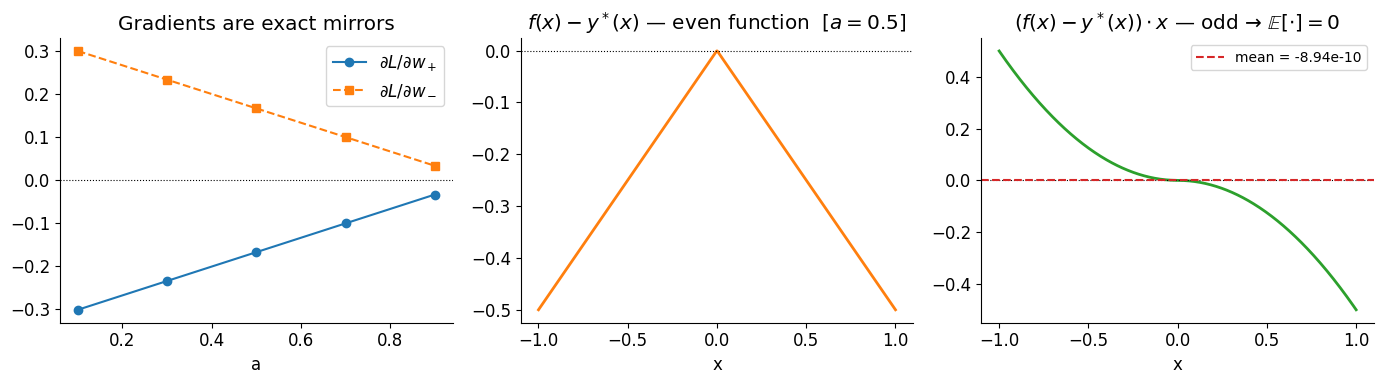

In [4]:
# Three-panel plot:
# (left)  ∂L/∂w+ and ∂L/∂w- vs a  (mirror images)
# (mid)   (f(x)-y*(x)) vs x        (even function)
# (right) (f(x)-y*(x))·x vs x      (odd function, expectation = 0)

a_vals = [r[0] for r in sweep_results]
gp_vals = [r[1] for r in sweep_results]
gn_vals = [r[2] for r in sweep_results]

# Use a=0.5 for the function plots
a_demo = 0.5
x_p = torch.linspace(-1, 1, 600)
f_demo = (torch.relu(a_demo * x_p) + torch.relu(-a_demo * x_p)
          + f_fixed(x_p)).detach()
err    = f_demo - target(x_p)
err_x  = err * x_p

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Left
axes[0].plot(a_vals, gp_vals, "o-", label=r"$\partial L/\partial w_+$")
axes[0].plot(a_vals, gn_vals, "s--", label=r"$\partial L/\partial w_-$")
axes[0].axhline(0, color="k", lw=0.8, ls=":")
axes[0].set_xlabel("a")
axes[0].set_title("Gradients are exact mirrors")
axes[0].legend()

# Mid
axes[1].plot(x_p.numpy(), err.numpy(), lw=2, color="tab:orange")
axes[1].axhline(0, color="k", lw=0.8, ls=":")
axes[1].set_xlabel("x")
axes[1].set_title(r"$f(x)-y^*(x)$ — even function  $[a=0.5]$")

# Right
axes[2].plot(x_p.numpy(), err_x.numpy(), lw=2, color="tab:green")
axes[2].axhline(0, color="k", lw=0.8, ls=":")
axes[2].axhline(err_x.mean().item(), color="tab:red", ls="--",
                label=f"mean = {err_x.mean().item():.2e}")
axes[2].set_xlabel("x")
axes[2].set_title(r"$(f(x)-y^*(x))\cdot x$ — odd → $\mathbb{E}[\cdot]=0$")
axes[2].legend(fontsize=10)

plt.tight_layout()
plt.savefig("fig_partA.png", dpi=150)
plt.show()

## Part B — Frozen pair + capacity argument

In [5]:
class SixNeuronNet(torch.nn.Module):
    """
    6-neuron 1-D ReLU network organised as 3 symmetric pairs.
    Pair 0 (neurons 0-1) can be frozen. Pairs 1-2 (neurons 2-5) are learnable.
    Symmetric-pair structure guarantees f(x) is always even → pair gradient sum = 0.
    """
    def __init__(self, freeze_pair: bool = True):
        super().__init__()
        self.freeze_pair = freeze_pair

        # Frozen pair: w=(0.5,−0.5), b=0, v=1
        w_pair = torch.tensor([0.5, -0.5])
        b_pair = torch.tensor([0.0,  0.0])
        v_pair = torch.tensor([1.0,  1.0])

        if freeze_pair:
            self.register_buffer("w_pair", w_pair)
            self.register_buffer("b_pair", b_pair)
            self.register_buffer("v_pair", v_pair)
        else:
            self.w_pair = torch.nn.Parameter(w_pair.clone())
            self.b_pair = torch.nn.Parameter(b_pair.clone())
            self.v_pair = torch.nn.Parameter(v_pair.clone())

        # Free symmetric pairs — each pair (w, −w, b, b, v)
        # Initialise near zero so learning starts fresh
        self.w_free = torch.nn.Parameter(torch.tensor([0.5, 0.7]))   # shape (2,)
        self.b_free = torch.nn.Parameter(torch.tensor([-0.2, -0.5])) # shape (2,) — start negative
        self.v_free = torch.nn.Parameter(torch.ones(2))              # shape (2,)

    def _pair_output(self, x, w, b, v):
        """Output of one symmetric pair: v*(relu(w*x+b) + relu(−w*x+b))."""
        return v * (torch.relu(w * x + b) + torch.relu(-w * x + b))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Frozen pair (vectorised)
        pre_p = x.unsqueeze(1) * self.w_pair + self.b_pair   # (N, 2)
        f_p   = (torch.relu(pre_p) * self.v_pair).sum(1)      # (N,)
        # Free symmetric pairs
        f_a = self._pair_output(x, self.w_free[0], self.b_free[0], self.v_free[0])
        f_b = self._pair_output(x, self.w_free[1], self.b_free[1], self.v_free[1])
        return f_p + f_a + f_b

    def pair_grad_sum(self, x: torch.Tensor, y: torch.Tensor) -> float:
        """
        Algebraic sum of frozen-pair gradients: |∂L/∂w+ + ∂L/∂w-|.
        Should be machine-zero when f is even (proved in Part A).
        """
        w_p = self.w_pair[0].clone().requires_grad_(True)   # w+
        w_n = self.w_pair[1].clone().requires_grad_(True)   # w− = −w+

        with torch.enable_grad():
            pre = x.unsqueeze(1) * torch.stack([w_p, w_n]) + self.b_pair
            f_frozen = (torch.relu(pre) * self.v_pair).sum(1)

            # Free pairs: use detached weights so grad flows only through frozen pair
            f_a = self._pair_output(x,
                                    self.w_free[0].detach(),
                                    self.b_free[0].detach(),
                                    self.v_free[0].detach())
            f_b = self._pair_output(x,
                                    self.w_free[1].detach(),
                                    self.b_free[1].detach(),
                                    self.v_free[1].detach())
            f   = f_frozen + f_a + f_b
            loss = ((f - y) ** 2).mean()
            g_p, g_n = torch.autograd.grad(loss, [w_p, w_n])

        return (g_p + g_n).abs().item()

    def pair_grad_norm(self, x: torch.Tensor, y: torch.Tensor) -> float:
        """
        L2 norm of individual frozen-pair gradients (NOT the sum).
        Non-zero even when sum is zero — shows units DO receive gradient signal.
        """
        w_p = self.w_pair[0].clone().requires_grad_(True)
        w_n = self.w_pair[1].clone().requires_grad_(True)

        with torch.enable_grad():
            pre = x.unsqueeze(1) * torch.stack([w_p, w_n]) + self.b_pair
            f_frozen = (torch.relu(pre) * self.v_pair).sum(1)
            f_a = self._pair_output(x,
                                    self.w_free[0].detach(),
                                    self.b_free[0].detach(),
                                    self.v_free[0].detach())
            f_b = self._pair_output(x,
                                    self.w_free[1].detach(),
                                    self.b_free[1].detach(),
                                    self.v_free[1].detach())
            f   = f_frozen + f_a + f_b
            loss = ((f - y) ** 2).mean()
            g_p, g_n = torch.autograd.grad(loss, [w_p, w_n])

        return (g_p.abs() + g_n.abs()).item()

# Quick sanity checks
_net = SixNeuronNet(freeze_pair=True)
_x   = sample_uniform(16)
_out = _net(_x)
assert _out.shape == (16,), f"Expected (16,), got {_out.shape}"
# Verify output is even: f(x) == f(-x)
_x2 = torch.linspace(-1, 1, 200)
_diff = (_net(_x2) - _net(-_x2)).abs().max().item()
assert _diff < 1e-6, f"Output not even: max |f(x)-f(-x)| = {_diff}"
print(f"SixNeuronNet OK. Even-function check: max |f(x)-f(−x)| = {_diff:.2e}")

SixNeuronNet OK. Even-function check: max |f(x)-f(−x)| = 0.00e+00


In [6]:
STEPS_B   = 10_000
LR_B      = 1e-3
LOG_EVERY = 200

torch.manual_seed(42)
net_b = SixNeuronNet(freeze_pair=True)
opt_b = torch.optim.Adam(
    [net_b.w_free, net_b.b_free, net_b.v_free], lr=LR_B
)

log_step_b, log_loss_b       = [], []
log_grad_sum_b, log_grad_norm_b = [], []   # algebraic sum vs individual norm
log_grad_free_b               = []

# Symmetric evaluation grid (used for exact gradient-sum check)
_x_half  = torch.linspace(1e-4, 1.0 - 1e-4, 50_000)
_x_sym   = torch.cat([-_x_half.flip(0), _x_half])   # perfectly symmetric
_y_sym   = target(_x_sym)

for step in range(STEPS_B):
    x = sample_uniform()
    y = target(x)

    loss = ((net_b(x) - y) ** 2).mean()
    opt_b.zero_grad()
    loss.backward()

    gf = (net_b.w_free.grad.norm()
        + net_b.b_free.grad.norm()
        + net_b.v_free.grad.norm()).item()
    opt_b.step()

    if step % LOG_EVERY == 0:
        with torch.no_grad():
            x_eval = sample_uniform(50_000)
            eval_loss = ((net_b(x_eval) - target(x_eval)) ** 2).mean().item()
        # Evaluate grad sum on symmetric grid → exact cancellation
        gs = net_b.pair_grad_sum(_x_sym, _y_sym)
        gn = net_b.pair_grad_norm(_x_sym, _y_sym)
        log_step_b.append(step)
        log_loss_b.append(eval_loss)
        log_grad_sum_b.append(gs)
        log_grad_norm_b.append(gn)
        log_grad_free_b.append(gf)

print(f"Final loss (frozen pair):           {log_loss_b[-1]:.6f}")
print(f"Final |∂L/∂w+ + ∂L/∂w-| (sum):   {log_grad_sum_b[-1]:.2e}")
print(f"Final |∂L/∂w+| + |∂L/∂w-| (norm): {log_grad_norm_b[-1]:.4f}")

assert log_loss_b[-1] > 0.0001, \
    f"Loss should plateau (2 free pairs can't fit 3-kink residual perfectly), got {log_loss_b[-1]}"
assert log_grad_sum_b[-1] < 1e-10, \
    f"|grad sum| should be machine zero (f is even, symmetric grid), got {log_grad_sum_b[-1]:.2e}"
print("✓ PASS: loss plateau verified | algebraic gradient sum is machine zero")

Final loss (frozen pair):           0.000686
Final |∂L/∂w+ + ∂L/∂w-| (sum):   5.82e-11
Final |∂L/∂w+| + |∂L/∂w-| (norm): 0.0015
✓ PASS: loss plateau verified | algebraic gradient sum is machine zero


In [7]:
STEPS_CF = 3_000

net_cf = SixNeuronNet(freeze_pair=False)
with torch.no_grad():
    net_cf.w_pair.copy_(net_b.w_pair)
    net_cf.b_pair.copy_(net_b.b_pair)
    net_cf.v_pair.copy_(net_b.v_pair)
    net_cf.w_free.copy_(net_b.w_free)
    net_cf.b_free.copy_(net_b.b_free)
    net_cf.v_free.copy_(net_b.v_free)

opt_cf = torch.optim.Adam(net_cf.parameters(), lr=LR_B)

log_step_cf, log_loss_cf = [], []

for step in range(STEPS_CF):
    x = sample_uniform()
    y = target(x)
    loss = ((net_cf(x) - y) ** 2).mean()
    opt_cf.zero_grad()
    loss.backward()
    opt_cf.step()

    if step % 100 == 0:
        with torch.no_grad():
            x_eval = sample_uniform(50_000)
            eval_loss = ((net_cf(x_eval) - target(x_eval)) ** 2).mean().item()
        log_step_cf.append(STEPS_B + step)
        log_loss_cf.append(eval_loss)

final_cf_loss = log_loss_cf[-1]
print(f"Counterfactual final loss: {final_cf_loss:.2e}")
assert final_cf_loss < 0.05, \
    f"Expected loss to drop after unfreeze, got {final_cf_loss:.2e}"
print("✓ PASS: unfreezing allows loss to fall — stagnation was capacity-driven")

Counterfactual final loss: 2.83e-12
✓ PASS: unfreezing allows loss to fall — stagnation was capacity-driven


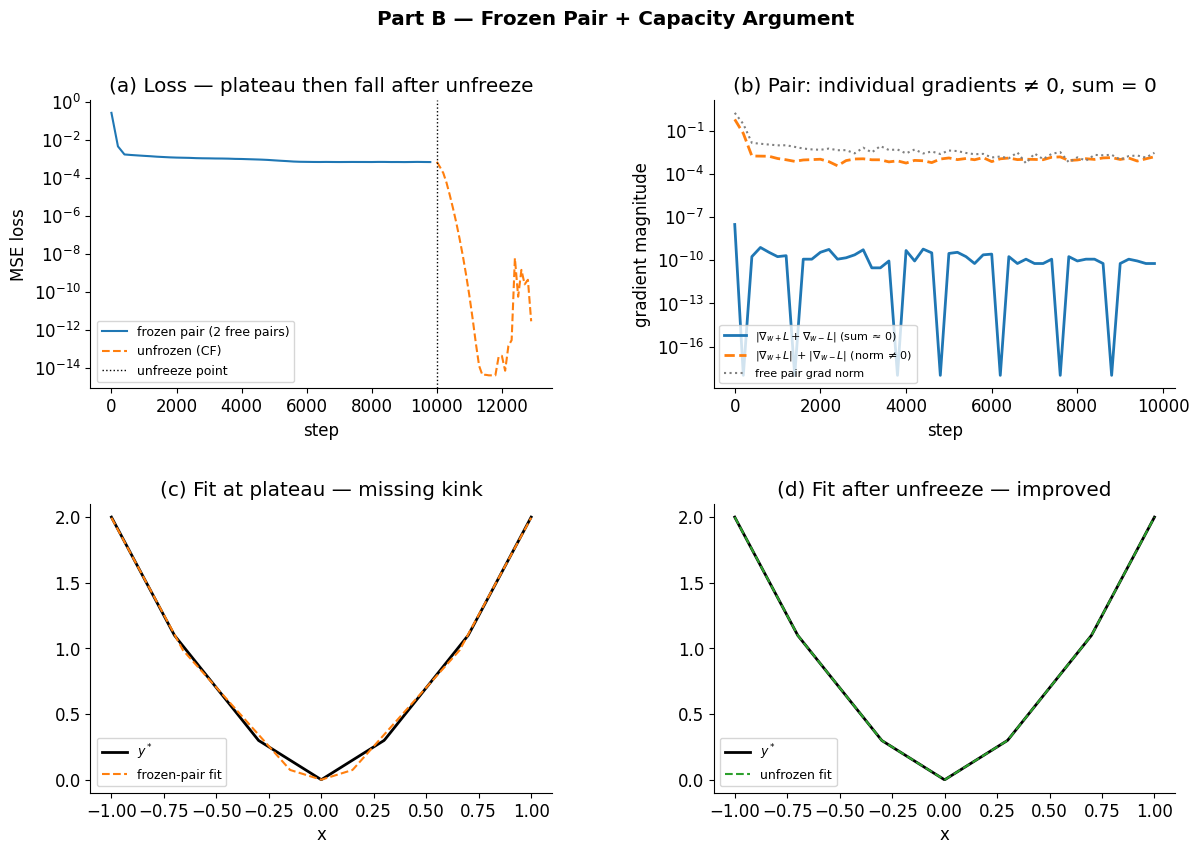

In [8]:
x_p = torch.linspace(-1, 1, 600)
y_p = target(x_p)

with torch.no_grad():
    f_plateau = net_b(x_p)
    f_cf      = net_cf(x_p)

fig = plt.figure(figsize=(14, 9))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.4, wspace=0.35)

# (a) loss over steps
ax_a = fig.add_subplot(gs[0, 0])
ax_a.semilogy(log_step_b,  log_loss_b,  label="frozen pair (2 free pairs)")
ax_a.semilogy(log_step_cf, log_loss_cf, label="unfrozen (CF)", ls="--")
ax_a.axvline(STEPS_B, color="k", ls=":", lw=1, label="unfreeze point")
ax_a.set_xlabel("step"); ax_a.set_ylabel("MSE loss")
ax_a.set_title("(a) Loss — plateau then fall after unfreeze")
ax_a.legend(fontsize=9)

# (b) gradient: algebraic sum (≈0) vs individual norm (non-zero)
ax_b = fig.add_subplot(gs[0, 1])
ax_b.semilogy(log_step_b, [max(v, 1e-18) for v in log_grad_sum_b],
              label=r"|$\nabla_{w+}L + \nabla_{w-}L$| (sum ≈ 0)", lw=2)
ax_b.semilogy(log_step_b, log_grad_norm_b,
              label=r"|$\nabla_{w+}L$| + |$\nabla_{w-}L$| (norm ≠ 0)", ls="--", lw=2)
ax_b.semilogy(log_step_b, log_grad_free_b,
              label="free pair grad norm", ls=":", lw=1.5, color="gray")
ax_b.set_xlabel("step"); ax_b.set_ylabel("gradient magnitude")
ax_b.set_title("(b) Pair: individual gradients ≠ 0, sum = 0")
ax_b.legend(fontsize=8)

# (c) fit at plateau
ax_c = fig.add_subplot(gs[1, 0])
ax_c.plot(x_p.numpy(), y_p.numpy(), "k-", lw=2, label=r"$y^*$")
ax_c.plot(x_p.numpy(), f_plateau.numpy(), "tab:orange", ls="--", label="frozen-pair fit")
ax_c.set_xlabel("x"); ax_c.set_title("(c) Fit at plateau — missing kink")
ax_c.legend(fontsize=9)

# (d) fit after unfreeze
ax_d = fig.add_subplot(gs[1, 1])
ax_d.plot(x_p.numpy(), y_p.numpy(), "k-", lw=2, label=r"$y^*$")
ax_d.plot(x_p.numpy(), f_cf.numpy(), "tab:green", ls="--", label="unfrozen fit")
ax_d.set_xlabel("x"); ax_d.set_title("(d) Fit after unfreeze — improved")
ax_d.legend(fontsize=9)

plt.suptitle("Part B — Frozen Pair + Capacity Argument", fontweight="bold")
plt.savefig("fig_partB.png", dpi=150)
plt.show()

## Part C — Full LoP replay

In [9]:
class FlexNet(torch.nn.Module):
    """6-neuron 1D ReLU network, all parameters free."""
    def __init__(self):
        super().__init__()
        self.w = torch.nn.Parameter(torch.randn(6) * 0.3)
        self.b = torch.nn.Parameter(torch.zeros(6))
        self.v = torch.nn.Parameter(torch.randn(6) * 0.3)

    def forward(self, x):
        pre = x.unsqueeze(1) * self.w + self.b   # (N, 6)
        return (torch.relu(pre) * self.v).sum(1)  # (N,)


STEPS_LOAD = 3_000
LR_C       = 1e-3

# Fresh 6-neuron network, all free
torch.manual_seed(49)
net_c = FlexNet()
opt_c = torch.optim.Adam(net_c.parameters(), lr=LR_C)

# ── Phase 1: y_pos = relu(x) ──────────────────────────────────────────────────────────────────────────────
log_c_step, log_c_loss, log_c_w = [], [], []

for step in range(STEPS_LOAD):
    x  = sample_uniform()
    y  = torch.relu(x)
    loss = ((net_c(x) - y) ** 2).mean()
    opt_c.zero_grad(); loss.backward(); opt_c.step()
    if step % 50 == 0:
        log_c_step.append(step)
        log_c_loss.append(loss.item())
        log_c_w.append(net_c.w.detach().clone())

phase1_end = len(log_c_step)
print(f"Phase 1 done. w values: {net_c.w.detach().numpy().round(3)}")

# ── Phase 2: y_neg = relu(-x) ──────────────────────────────────────────────────────────────────────────────
for step in range(STEPS_LOAD):
    x  = sample_uniform()
    y  = torch.relu(-x)
    loss = ((net_c(x) - y) ** 2).mean()
    opt_c.zero_grad(); loss.backward(); opt_c.step()
    if step % 50 == 0:
        log_c_step.append(STEPS_LOAD + step)
        log_c_loss.append(loss.item())
        log_c_w.append(net_c.w.detach().clone())

phase2_end = len(log_c_step)
print(f"Phase 2 done. w values: {net_c.w.detach().numpy().round(3)}")

# ── Identify organic antipodal pair ───────────────────────────────────────────────────────────────────────────────
w_final = net_c.w.detach()
idx_pos  = w_final.argmax().item()
idx_neg  = w_final.argmin().item()
w_max    = w_final[idx_pos].item()
w_min    = w_final[idx_neg].item()
asymmetry = abs(w_max + w_min) / (abs(w_max) + 1e-8)
print(f"Antipodal pair: neuron {idx_pos} (w={w_max:.3f}), neuron {idx_neg} (w={w_min:.3f})")
print(f"Antipodal asymmetry ratio: {asymmetry:.3f}  (smaller = more antipodal)")


Phase 1 done. w values: [-0.344  0.856 -0.     0.382 -0.234  0.626]


Phase 2 done. w values: [-0.924  0.477 -0.     0.184 -0.764  0.815]
Antipodal pair: neuron 5 (w=0.815), neuron 0 (w=-0.924)
Antipodal asymmetry ratio: 0.133  (smaller = more antipodal)


In [10]:
STEPS_TRAP = 3_000

# ── Baseline: fresh FlexNet trained directly on y* ──────────────────────────────────────────────────────────────────────────────
torch.manual_seed(42)
net_baseline = FlexNet()
opt_base     = torch.optim.Adam(net_baseline.parameters(), lr=LR_C)
log_base_step, log_base_loss = [], []

for step in range(STEPS_TRAP):
    x = sample_uniform()
    y = target(x)
    loss = ((net_baseline(x) - y) ** 2).mean()
    opt_base.zero_grad(); loss.backward(); opt_base.step()
    if step % 50 == 0:
        log_base_step.append(step)
        log_base_loss.append(loss.item())

print(f"Baseline final loss: {log_base_loss[-1]:.4f}")

# ── Trap phase: loaded net on y* ────────────────────────────────────────────────────────────────────────────────
log_grad_c   = {i: [] for i in range(6)}   # per-neuron |∂L/∂w_k|
log_trap_step, log_trap_loss = [], []

for step in range(STEPS_TRAP):
    x = sample_uniform()
    y = target(x)
    loss = ((net_c(x) - y) ** 2).mean()
    opt_c.zero_grad()
    loss.backward()

    for i in range(6):
        log_grad_c[i].append(net_c.w.grad[i].abs().item())

    opt_c.step()
    if step % 50 == 0:
        log_trap_step.append(2 * STEPS_LOAD + step)
        log_trap_loss.append(loss.item())

print(f"Loaded net final loss (Phase 3):  {log_trap_loss[-1]:.4f}")
print(f"Baseline final loss:              {log_base_loss[-1]:.4f}")

# Gradient of the antipodal pair in Phase 3
pair_grad_trap = [(log_grad_c[idx_pos][s] + log_grad_c[idx_neg][s]) / 2
                  for s in range(STEPS_TRAP)]
mean_pair_grad = float(np.mean(pair_grad_trap))
mean_other_grad = float(np.mean([
    np.mean(log_grad_c[i]) for i in range(6) if i not in (idx_pos, idx_neg)
]))
print(f"Mean |pair w-grad| in Phase 3:  {mean_pair_grad:.2e}")
print(f"Mean |other w-grad| in Phase 3: {mean_other_grad:.2e}")
print(f"Ratio (pair/other):             {mean_pair_grad / (mean_other_grad + 1e-12):.3f}")


Baseline final loss: 0.0019


Loaded net final loss (Phase 3):  0.0032
Baseline final loss:              0.0019
Mean |pair w-grad| in Phase 3:  1.46e-03
Mean |other w-grad| in Phase 3: 5.68e-03
Ratio (pair/other):             0.258


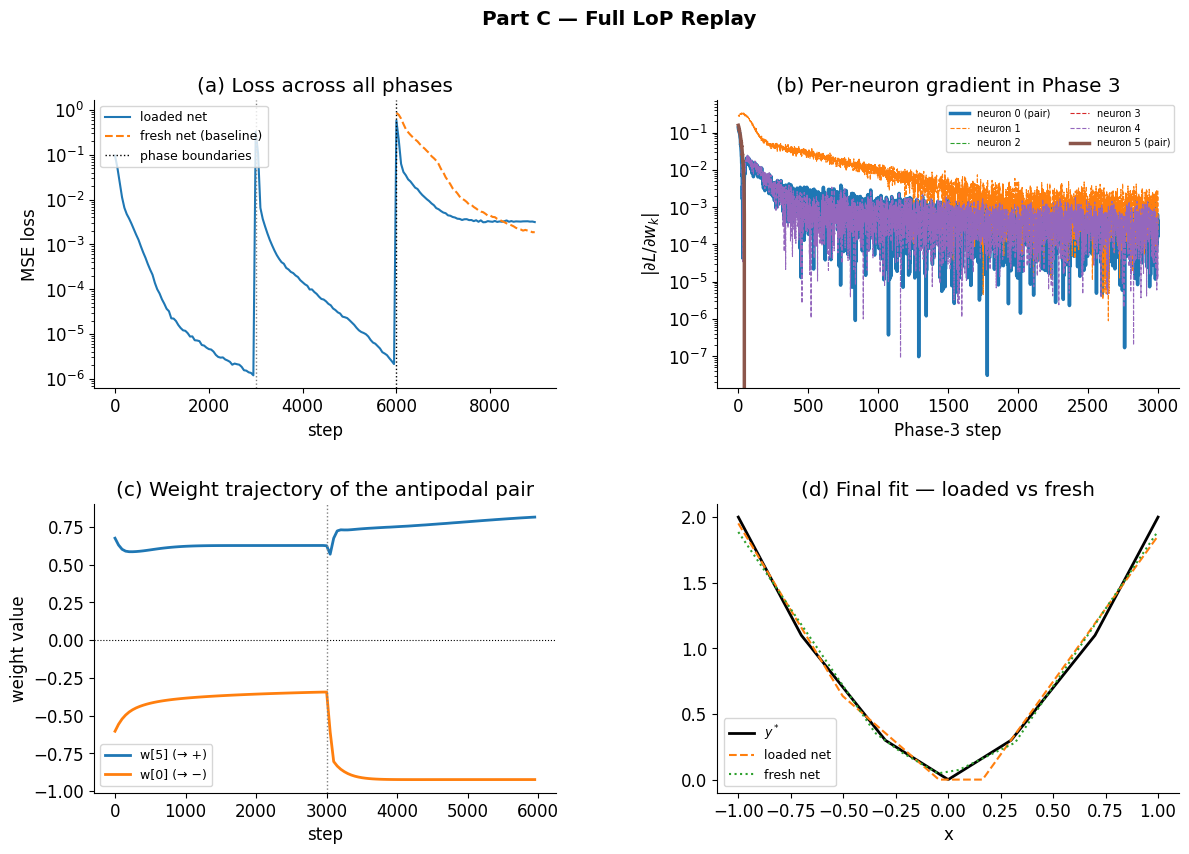


Summary:
  Loaded net Phase-3 final loss:  0.0032
  Fresh net Phase-3 final loss:   0.0019
  Pair gradient ratio (pair/other): 0.258


In [11]:
x_p = torch.linspace(-1, 1, 600)
y_p = target(x_p)
with torch.no_grad():
    f_loaded   = net_c(x_p)
    f_baseline = net_baseline(x_p)

# Weight trajectory
w_traj = torch.stack(log_c_w).numpy()   # (T, 6)

fig = plt.figure(figsize=(14, 9))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.4, wspace=0.35)

# (a) loss across all phases
ax_a = fig.add_subplot(gs[0, 0])
all_loaded_steps = log_c_step + log_trap_step
all_loaded_loss  = log_c_loss + log_trap_loss
ax_a.semilogy(all_loaded_steps, all_loaded_loss, label="loaded net")
baseline_offset = [2 * STEPS_LOAD + s for s in log_base_step]
ax_a.semilogy(baseline_offset, log_base_loss, label="fresh net (baseline)", ls="--")
ax_a.axvline(STEPS_LOAD,     color="gray", ls=":", lw=1)
ax_a.axvline(2 * STEPS_LOAD, color="k",    ls=":", lw=1, label="phase boundaries")
ax_a.set_xlabel("step"); ax_a.set_ylabel("MSE loss")
ax_a.set_title("(a) Loss across all phases")
ax_a.legend(fontsize=9)

# (b) per-neuron gradient norms in Phase 3
steps_trap_all = list(range(STEPS_TRAP))
ax_b = fig.add_subplot(gs[0, 1])
for i in range(6):
    is_pair = i in (idx_pos, idx_neg)
    lw  = 2.5 if is_pair else 0.8
    ls  = "-"  if is_pair else "--"
    lbl = f"neuron {i} (pair)" if is_pair else f"neuron {i}"
    ax_b.semilogy(steps_trap_all, log_grad_c[i], lw=lw, ls=ls, label=lbl)
ax_b.set_xlabel("Phase-3 step"); ax_b.set_ylabel(r"|$\partial L/\partial w_k$|")
ax_b.set_title("(b) Per-neuron gradient in Phase 3")
ax_b.legend(fontsize=7, ncol=2)

# (c) weight trajectory of antipodal pair
ax_c = fig.add_subplot(gs[1, 0])
traj_steps = log_c_step[:phase2_end]
ax_c.plot(traj_steps, w_traj[:phase2_end, idx_pos], label=f"w[{idx_pos}] (→ +)", lw=2)
ax_c.plot(traj_steps, w_traj[:phase2_end, idx_neg], label=f"w[{idx_neg}] (→ −)", lw=2)
ax_c.axvline(STEPS_LOAD, color="gray", ls=":", lw=1)
ax_c.axhline(0, color="k", lw=0.8, ls=":")
ax_c.set_xlabel("step"); ax_c.set_ylabel("weight value")
ax_c.set_title("(c) Weight trajectory of the antipodal pair")
ax_c.legend(fontsize=9)

# (d) final function fit
ax_d = fig.add_subplot(gs[1, 1])
ax_d.plot(x_p.numpy(), y_p.numpy(),        "k-",         lw=2,   label=r"$y^*$")
ax_d.plot(x_p.numpy(), f_loaded.numpy(),   "tab:orange", ls="--", lw=1.5, label="loaded net")
ax_d.plot(x_p.numpy(), f_baseline.numpy(), "tab:green",  ls=":",  lw=1.5, label="fresh net")
ax_d.set_xlabel("x"); ax_d.set_title("(d) Final fit — loaded vs fresh")
ax_d.legend(fontsize=9)

plt.suptitle("Part C — Full LoP Replay", fontweight="bold")
plt.savefig("fig_partC.png", dpi=150)
plt.show()

print(f"\nSummary:")
print(f"  Loaded net Phase-3 final loss:  {log_trap_loss[-1]:.4f}")
print(f"  Fresh net Phase-3 final loss:   {log_base_loss[-1]:.4f}")
print(f"  Pair gradient ratio (pair/other): {mean_pair_grad / (mean_other_grad + 1e-12):.3f}")
